In [24]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt
import numpy as np
# ==========================================
# 1. PRÉTRAITEMENT ET CHARGEMENT DES DONNÉES
# ==========================================

# Définition des transformations : redimensionnement en 32x32, conversion en nuances de gris (1 canal),
# conversion en tenseur PyTorch et normalisation entre -1 et 1.
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])
#2 Chargement des datasets d'entraînement et de test à partir du dossier extrait 'AMHCD_64'
full_dataset = torchvision.datasets.ImageFolder(
    root=r'C:\Users\pc\Downloads\tifingh\AMHCD_64\AMHCD_64', 
    transform=transform
)

# تقسيم البيانات تلقائياً: 80% للتدريب و 20% للاختبار
train_size = int(0.8 * len(full_dataset))
test_size = len(full_dataset) - train_size
train_dataset, test_dataset = random_split(full_dataset, [train_size, test_size])
# 3Création des chargeurs de données (DataLoaders) par paquets (batchs) de 64 images
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print(f" Données chargées avec succès ! Nombre de classes (Tifinagh): {len(full_dataset.classes)}")

 Données chargées avec succès ! Nombre de classes (Tifinagh): 33


In [25]:
import torch.nn as nn
import torch.nn.functional as F

class LeNet5_Tifinagh(nn.Module):
    def __init__(self):
        super(LeNet5_Tifinagh, self).__init__()
        
        # C1 : Couche de convolution (Entrée: 1 canal, Sortie: 6 filtres, Noyau: 5x5)
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=6, kernel_size=5, stride=1)
        
        # S2 : Sous-échantillonnage par Average Pooling (2x2)
        self.pool2 = nn.AvgPool2d(kernel_size=2, stride=2)
        
        # C3 : Deuxième couche de convolution (6 entrées, 16 filtres, Noyau: 5x5)
        self.conv3 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5, stride=1)
        
        # S4 : Deuxième sous-échantillonnage par Average Pooling (2x2)
        self.pool4 = nn.AvgPool2d(kernel_size=2, stride=2)
        
        # C5 : Couche convolutionnelle agissant comme une couche pleinement connectée (16 vers 120 neurones)
        self.conv5 = nn.Conv2d(in_channels=16, out_channels=120, kernel_size=5, stride=1)
        
        # F6 : Couche dense (Fully Connected) de 120 à 84 neurones
        self.fc6 = nn.Linear(120, 84)
        
        # Sortie : Couche finale de classification (84 vers 33 classes pour l'alphabet Tifinagh)
        self.fc_out = nn.Linear(84, 33)

    def forward(self, x):
        # Application des convolutions suivies de fonctions d'activation ReLU
        x = F.relu(self.conv1(x))
        x = self.pool2(x)
        x = F.relu(self.conv3(x))
        x = self.pool4(x)
        x = F.relu(self.conv5(x))
        
        # Aplatissement (Flatten) du tenseur pour le passer aux couches denses
        x = x.view(x.size(0), -1)
        
        x = F.relu(self.fc6(x))
        x = self.fc_out(x)
        return x

# Instanciation du modèle
model = LeNet5_Tifinagh()
print(" Modèle LeNet-5 initialisé avec succès !")
print(model)

 Modèle LeNet-5 initialisé avec succès !
LeNet5_Tifinagh(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (conv3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (pool4): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (conv5): Conv2d(16, 120, kernel_size=(5, 5), stride=(1, 1))
  (fc6): Linear(in_features=120, out_features=84, bias=True)
  (fc_out): Linear(in_features=84, out_features=33, bias=True)
)


In [26]:
import torch.optim as optim

# 1. Définition de la fonction de perte (Loss) et de l'optimiseur (Adam)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 2. Définition du nombre d'époques (Epochs)
num_epochs = 20  # Vous pourrez l'augmenter plus tard si nécessaire

print(" Début de l'entraînement du modèle...")

# 3. Boucle d'entraînement
for epoch in range(num_epochs):
    model.train()  # Mettre le modèle en mode entraînement
    running_loss = 0.0
    correct = 0
    total = 0
    
    for i, data in enumerate(train_loader, 0):
        inputs, labels = data
        
        # Remise à zéro des gradients
        optimizer.zero_grad()
        
        # Passage en avant (Forward pass)
        outputs = model(inputs)
        
        # Calcul de l'erreur (Loss)
        loss = criterion(outputs, labels)
        
        # Passage en arrière (Backward pass) et optimisation
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        
        # Calcul de la précision (Accuracy)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        
    epoch_loss = running_loss / len(train_loader)
    epoch_acc = 100. * correct / total
    
    print(f"Époque [{epoch+1}/{num_epochs}] ➔ Perte (Loss): {epoch_loss:.4f} | Précision (Accuracy): {epoch_acc:.2f}%")

print(" Entraînement terminé avec succès !")

 Début de l'entraînement du modèle...
Époque [1/20] ➔ Perte (Loss): 1.7679 | Précision (Accuracy): 51.78%
Époque [2/20] ➔ Perte (Loss): 0.5661 | Précision (Accuracy): 84.87%
Époque [3/20] ➔ Perte (Loss): 0.3750 | Précision (Accuracy): 89.77%
Époque [4/20] ➔ Perte (Loss): 0.2741 | Précision (Accuracy): 92.23%
Époque [5/20] ➔ Perte (Loss): 0.2169 | Précision (Accuracy): 93.81%
Époque [6/20] ➔ Perte (Loss): 0.1756 | Précision (Accuracy): 94.99%
Époque [7/20] ➔ Perte (Loss): 0.1497 | Précision (Accuracy): 95.65%
Époque [8/20] ➔ Perte (Loss): 0.1240 | Précision (Accuracy): 96.41%
Époque [9/20] ➔ Perte (Loss): 0.1120 | Précision (Accuracy): 96.66%
Époque [10/20] ➔ Perte (Loss): 0.0972 | Précision (Accuracy): 97.05%
Époque [11/20] ➔ Perte (Loss): 0.0894 | Précision (Accuracy): 97.28%
Époque [12/20] ➔ Perte (Loss): 0.0762 | Précision (Accuracy): 97.72%
Époque [13/20] ➔ Perte (Loss): 0.0688 | Précision (Accuracy): 97.91%
Époque [14/20] ➔ Perte (Loss): 0.0655 | Précision (Accuracy): 97.98%
Époqu

In [27]:
# ==========================================
# 4. ÉVALUATION DU MODÈLE SUR LE TEST SET
# ==========================================

model.eval()  # Mettre le modèle en mode évaluation
correct = 0
total = 0

# Désactivation du calcul des gradients pour accélérer et économiser la mémoire
with torch.no_grad():
    for data in test_loader:
        images, labels = data
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f" Précision du modèle sur les données de test (Test Accuracy): {accuracy:.2f}%")

 Précision du modèle sur les données de test (Test Accuracy): 96.60%


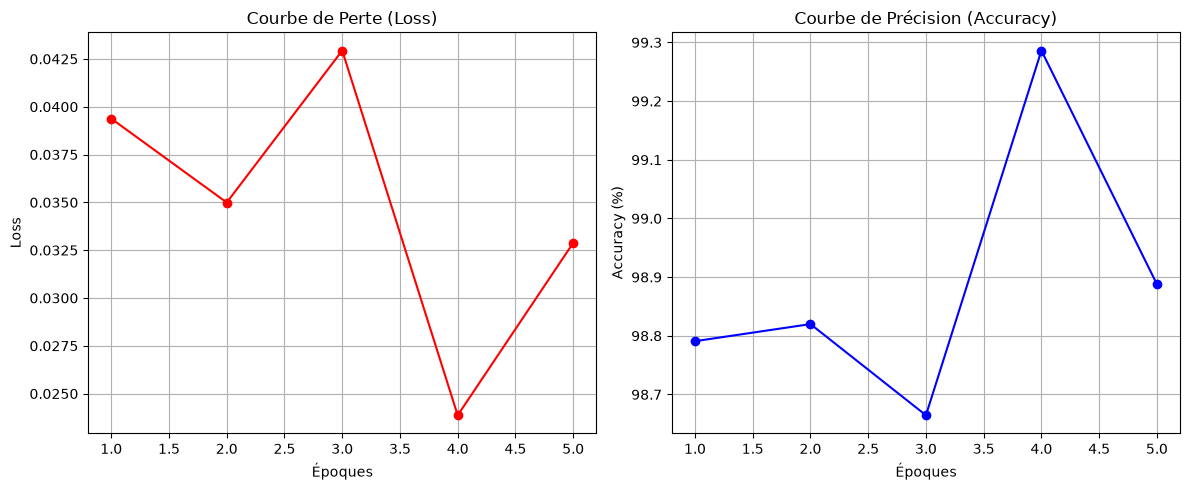

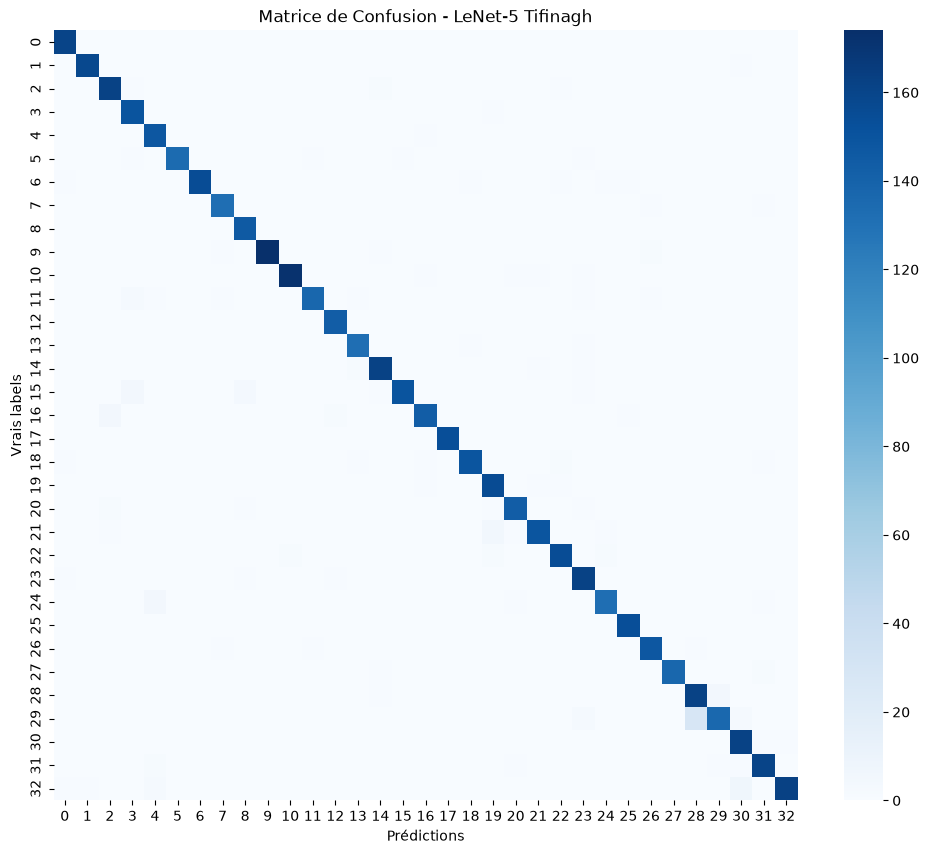

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# 1. Suivi des pertes (Loss) et précisions (Accuracy) au cours des époques
# (Note: Si vous avez enregistré ces valeurs dans des listes train_losses et train_accs durant l'entraînement, 
# vous pouvez directement les utiliser ici. Sinon, voici un exemple de structure si vous refaites l'entraînement avec stockage)

train_losses = []
train_accuracies = []

# Exemple de boucle avec stockage pour les graphiques :
num_epochs = 5 # Ou 50 selon votre choix
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for inputs, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        
    epoch_loss = running_loss / len(train_loader)
    epoch_acc = 100. * correct / total
    
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_acc)

# 2. Affichage des courbes de Loss et Accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, num_epochs+1), train_losses, marker='o', color='red')
plt.title('Courbe de Perte (Loss)')
plt.xlabel('Époques')
plt.ylabel('Loss')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(range(1, num_epochs+1), train_accuracies, marker='o', color='blue')
plt.title('Courbe de Précision (Accuracy)')
plt.xlabel('Époques')
plt.ylabel('Accuracy (%)')
plt.grid(True)

plt.tight_layout()
plt.show()

# 3. Calcul et affichage de la Matrice de Confusion
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=False, cmap='Blues')
plt.xlabel('Prédictions')
plt.ylabel('Vrais labels')
plt.title('Matrice de Confusion - LeNet-5 Tifinagh')
plt.show()

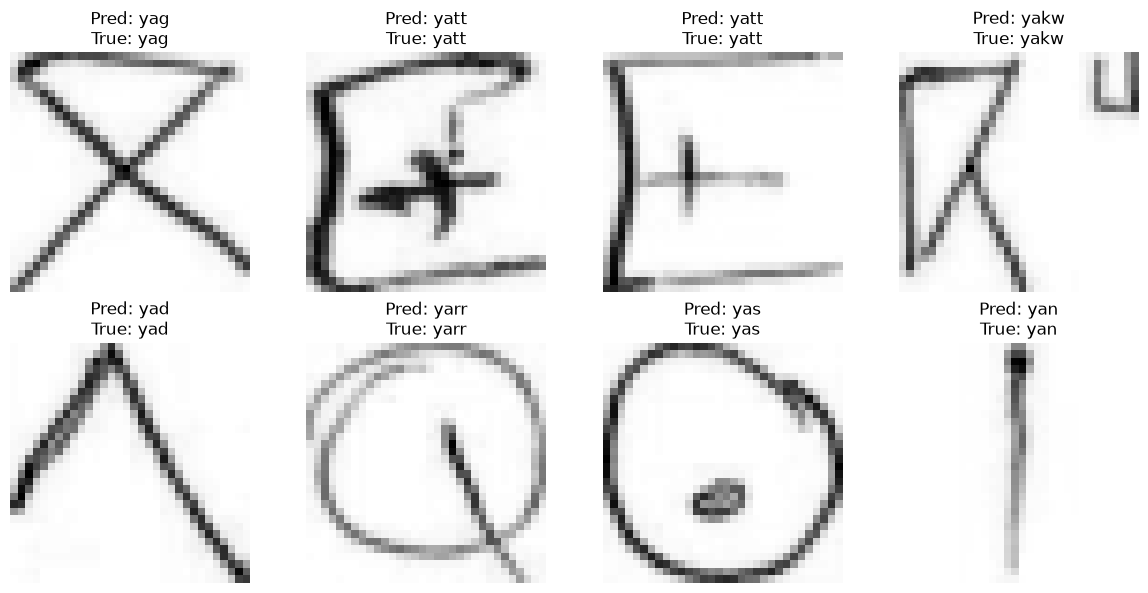

In [29]:
dataiter = iter(test_loader)
images, labels = next(dataiter)

outputs = model(images)
_, preds = torch.max(outputs, 1)

plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i+1)
    plt.imshow(images[i].squeeze(), cmap='gray')
    plt.title(f"Pred: {full_dataset.classes[preds[i]]}\nTrue: {full_dataset.classes[labels[i]]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

In [30]:
torch.save(model.state_dict(), 'lenet5_tifinagh_model.pth')
print("enrgestrele model et succese")

enrgestrele model et succese
